In [77]:
import pandas as pd
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from gensim.models.phrases import Phrases, Phraser
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import dateutil.parser
from nltk.sentiment.vader import SentimentIntensityAnalyzer

In [78]:
# 1) Read the file NYT headline.csv on python and drop the duplicates
nyt_df = pd.read_csv('C:/Users/nickt/Downloads/ECO482 Assignment 2/NYT_headlines.csv')
nyt_df = nyt_df.drop_duplicates()

# i prefer to convert dates to proper datetime objects


def clean_nyt_date(date_str):
    clean_str = date_str.replace('.', '').strip() + ' 2021'
    return pd.to_datetime(clean_str)

nyt_df['Date'] = nyt_df['date'].apply(clean_nyt_date)

# Sort the entire dataframe chronologically
nyt_df = nyt_df.sort_values('Date').reset_index(drop=True)

In [79]:
# 2) Combining the different headlines by day
daily_headlines = nyt_df.groupby('Date')['Headlines'].apply(lambda x: ' '.join(x)).reset_index()

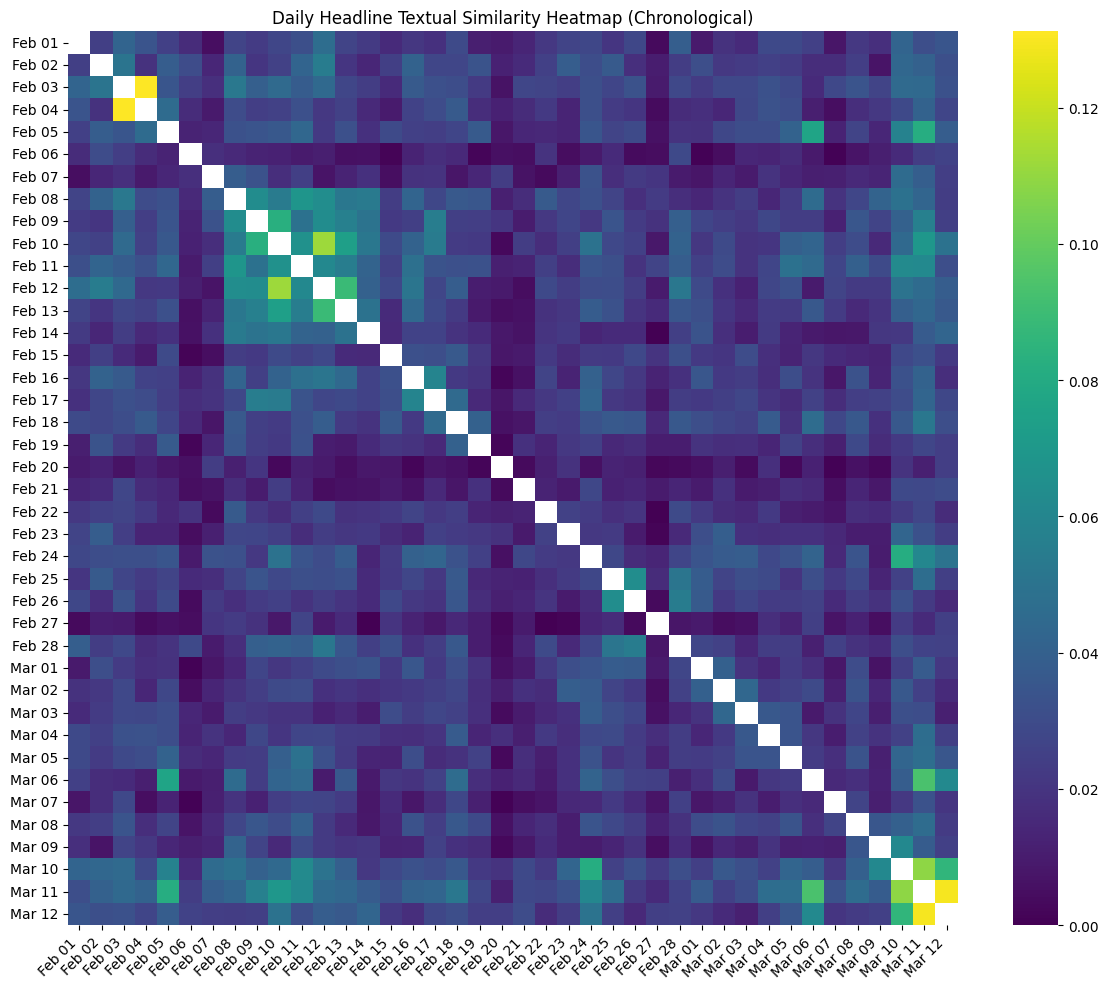

Top 3 most similar pairs of dates:
1. February 03 and February 04 (Similarity: 0.1312)
2. March 11 and March 12 (Similarity: 0.1296)
3. February 10 and February 12 (Similarity: 0.1122)


In [80]:
# 3) TF-IDF matrix, Collocations, and Similarity heatmap

# Tokenize the daily documents
tokenized_docs = [word_tokenize(doc.lower()) for doc in daily_headlines['Headlines']]
phrases = Phrases(tokenized_docs, min_count=1, threshold=1)
bigram = Phraser(phrases)
docs_with_collocations = [' '.join(bigram[doc]) for doc in tokenized_docs]

# finding the TF-IDF matrix
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(docs_with_collocations)
sim_matrix = cosine_similarity(tfidf_matrix)

# Format dates
date_labels = daily_headlines['Date'].dt.strftime('%b %d')

sim_matrix_plot = sim_matrix.copy()
np.fill_diagonal(sim_matrix_plot, np.nan)

# Plot heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(sim_matrix_plot, xticklabels=date_labels, yticklabels=date_labels, cmap='viridis')
plt.title('Daily Headline Textual Similarity Heatmap (Chronological)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Find the top 3 pairs of dates
np.fill_diagonal(sim_matrix, 0) # Ignore diagonal (same day)
upper_tri = np.triu(sim_matrix) # Ignore duplicates
flat_indices = np.argsort(upper_tri.flatten())[::-1]
top_3_idx = np.unravel_index(flat_indices[:3], upper_tri.shape)

print("Top 3 most similar pairs of dates:")
for i in range(3):
    idx1, idx2 = top_3_idx[0][i], top_3_idx[1][i]
    date1 = daily_headlines['Date'].iloc[idx1].strftime('%B %d')
    date2 = daily_headlines['Date'].iloc[idx2].strftime('%B %d')
    print(f"{i+1}. {date1} and {date2} (Similarity: {upper_tri[idx1, idx2]:.4f})")

In [81]:
# 4) Vocabulary
covid_vocab = ['covid', 'covid-19', 'coronavirus', 'pandemic', 'virus', 'vaccine', 'vaccines',
               'vaccination', 'fauci', 'quarantine']

In [82]:
# 5) Covid Uncertainty Index
def is_covid_related(text):
    text_lower = text.lower()
    return any(word in text_lower for word in covid_vocab)


nyt_df['is_covid'] = nyt_df['Headlines'].apply(is_covid_related)

# Create the covid index using the clean Date column
covid_index = nyt_df.groupby('Date')['is_covid'].mean().reset_index(name='covid_uncertainty_index')
print("\nCovid Uncertainty Index (Head):")
print(covid_index.head())


Covid Uncertainty Index (Head):
        Date  covid_uncertainty_index
0 2021-02-01                 0.086957
1 2021-02-02                 0.198276
2 2021-02-03                 0.148148
3 2021-02-04                 0.072289
4 2021-02-05                 0.081633


In [83]:
# 6) Coarse Economic Policy Uncertainty Index
econ_vocab = [
    "uncertainty", "uncertain", "economic", "economy", "congress", "deficit", "federal reserve",
    "legislation", "regulation", "white house", "uncertainties", "regulatory", "the fed"]


def is_econ_related(text):
    text_lower = text.lower()
    return any(word in text_lower for word in econ_vocab)


nyt_df['is_econ'] = nyt_df['Headlines'].apply(is_econ_related)

# Create the econ index using the clean Date column
econ_index = nyt_df.groupby('Date')['is_econ'].mean().reset_index(name='econ_policy_uncertainty_index')
print("\nEconomic Policy Uncertainty Index (Head):")
print(econ_index.head())


Economic Policy Uncertainty Index (Head):
        Date  econ_policy_uncertainty_index
0 2021-02-01                       0.000000
1 2021-02-02                       0.051724
2 2021-02-03                       0.046296
3 2021-02-04                       0.000000
4 2021-02-05                       0.061224


In [84]:
# 8) computing Return of S&P500
sp500_df = pd.read_csv('C:/Users/nickt/Downloads/ECO482 Assignment 2/SP500-1.csv')

# Clean the data
sp500_df['Adj Close'] = sp500_df['Adj Close**'].astype(str).str.replace(',', '').astype(float)
sp500_df['Date'] = pd.to_datetime(sp500_df['Date'], format='%d-%b-%y')
sp500_df = sp500_df.sort_values('Date').reset_index(drop=True)

# Calculate daily return (today price - previous day price) / previous day price
sp500_df['Return'] = sp500_df['Adj Close'].pct_change()
sp500_df['Date'] = pd.to_datetime(sp500_df['Date'], format='%d-%b-%y')

# Merge indices and returns
merged_df = pd.merge(covid_index, econ_index, on='Date')
merged_df = pd.merge(merged_df, sp500_df[['Date', 'Return']], on='Date', how='inner')

print(sp500_df['Return'].tail())

43   -0.005359
44    0.014155
45    0.006030
46    0.010395
47    0.001015
Name: Return, dtype: float64


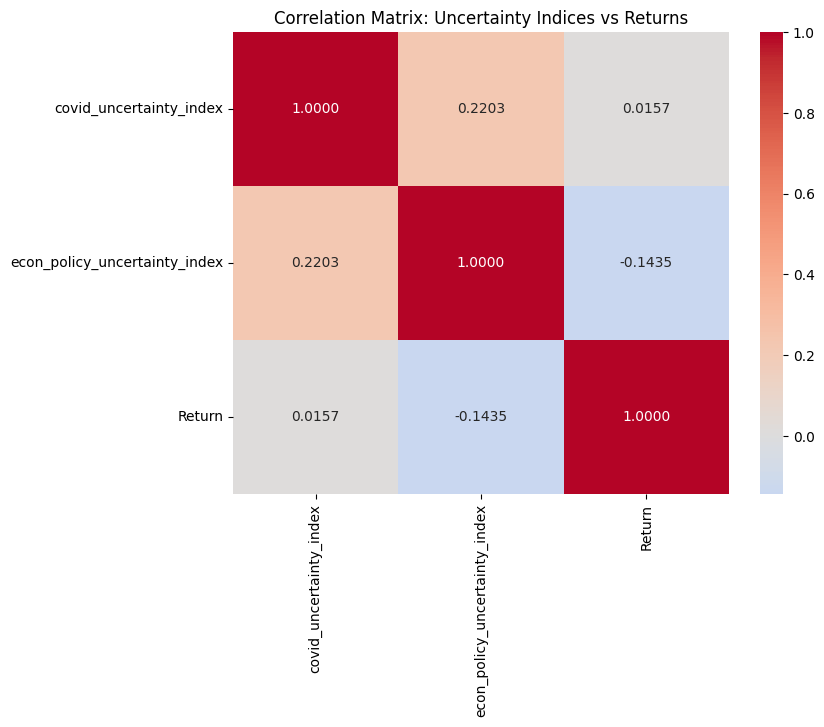

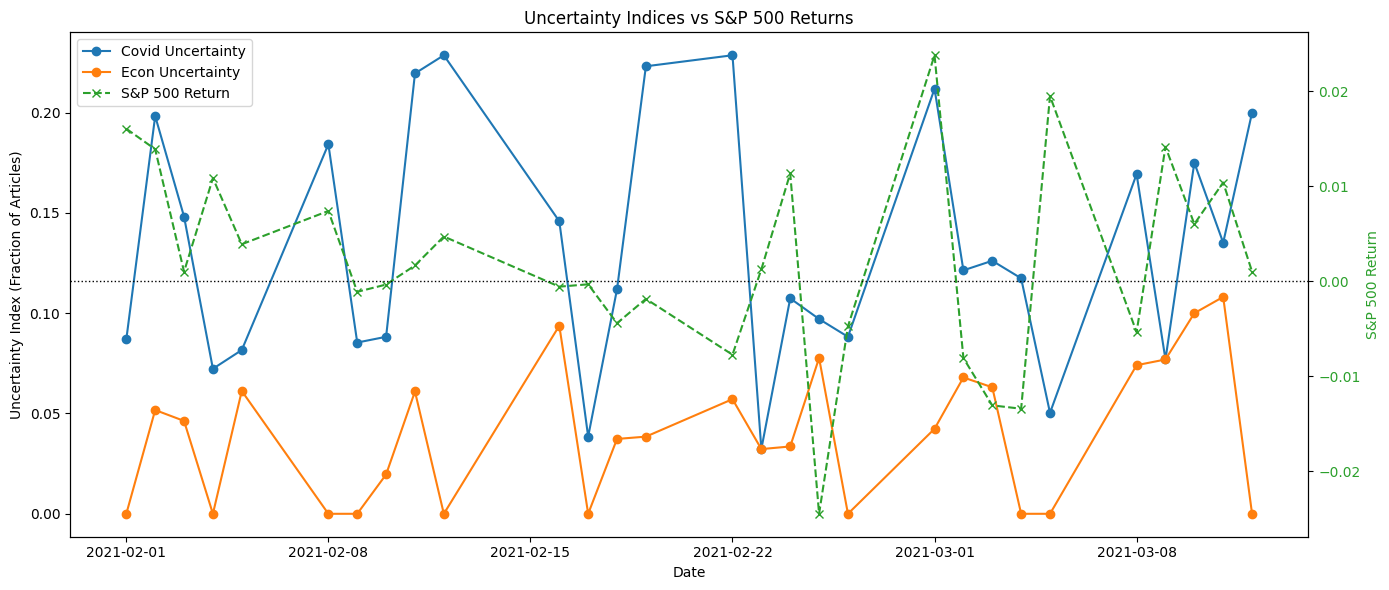

In [85]:
# 9) plot and correlations of uncertainty indices and S&P

# correlations
# Calculate the correlation matrix
correlation_matrix = merged_df[['covid_uncertainty_index', 'econ_policy_uncertainty_index', 'Return']].corr()

# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".4f", center=0)
plt.title('Correlation Matrix: Uncertainty Indices vs Returns')
plt.show()

# If you still want the table, simply put the variable name at the end of a cell
# (without print) to see a nicely formatted HTML table in Jupyter:
correlation_matrix

#Plot

fig, ax1 = plt.subplots(figsize=(14, 6))

# Primary Y-axis (Indices)
color1 = 'tab:blue'
color2 = 'tab:orange'
ax1.set_xlabel('Date')
ax1.set_ylabel('Uncertainty Index (Fraction of Articles)', color='black')
line1 = ax1.plot(merged_df['Date'], merged_df['covid_uncertainty_index'],
                 color=color1, label='Covid Uncertainty', marker='o')
line2 = ax1.plot(merged_df['Date'], merged_df['econ_policy_uncertainty_index'],
                 color=color2, label='Econ Uncertainty', marker='o')
ax1.tick_params(axis='y')

# Secondary Y-axis (S&P 500 Returns)
ax2 = ax1.twinx()
color3 = 'tab:green'
ax2.set_ylabel('S&P 500 Return', color=color3)
line3 = ax2.plot(merged_df['Date'], merged_df['Return'], color=color3, label='S&P 500 Return',
                 linestyle='dashed', marker='x')
ax2.tick_params(axis='y', labelcolor=color3)
ax2.axhline(0, color='black', linestyle=':', linewidth=1)

# Combine legends
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Uncertainty Indices vs S&P 500 Returns')
fig.tight_layout()
plt.show()

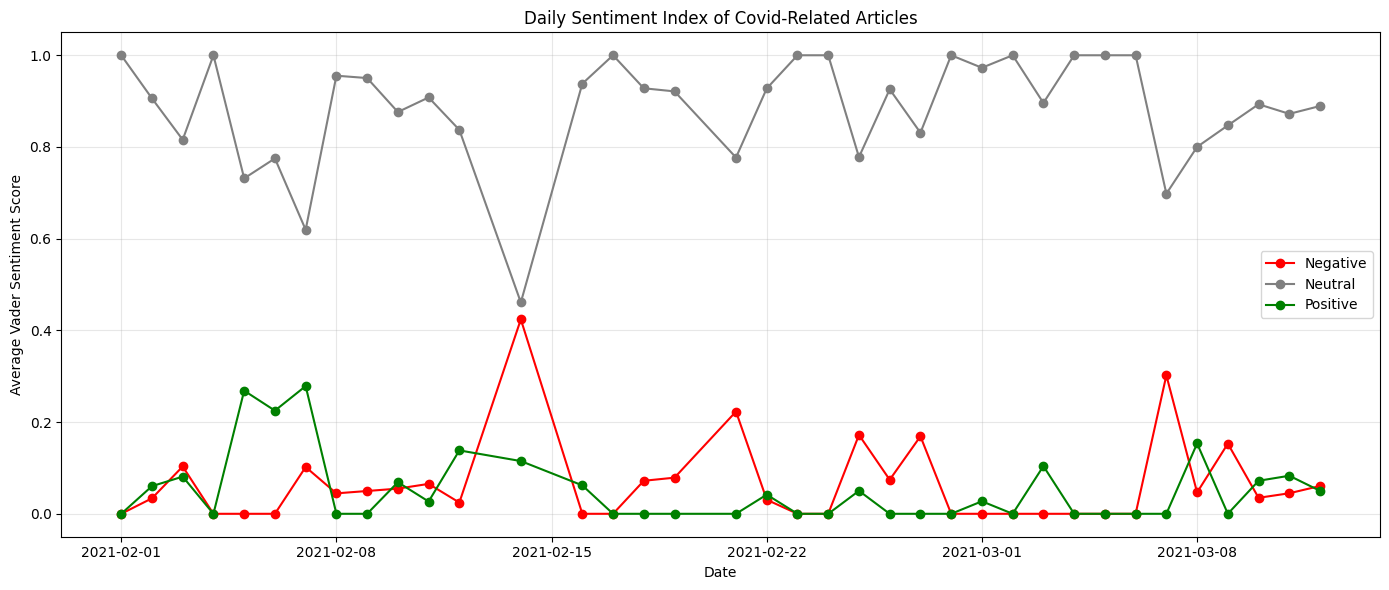


Aggregate Sentiment Over All Periods:
Negative    0.043993
Neutral     0.907792
Positive    0.048214
dtype: float64


In [86]:
# 10) Sentiment Analysis
sid = SentimentIntensityAnalyzer()


def get_sentiments(text):
    scores = sid.polarity_scores(text)
    return pd.Series([scores['neg'], scores['neu'], scores['pos']])


# only articles with a covid-related word
covid_articles = nyt_df[nyt_df['is_covid'] == True].copy()
covid_articles[['Negative', 'Neutral', 'Positive']] = covid_articles['Headlines'].apply(get_sentiments)

# Group by Date
daily_sentiment = covid_articles.groupby('Date')[['Negative', 'Neutral', 'Positive']].mean().reset_index()

# Plot as a line chart
plt.figure(figsize=(14, 6))
plt.plot(daily_sentiment['Date'], daily_sentiment['Negative'], label='Negative', color='red', marker='o')
plt.plot(daily_sentiment['Date'], daily_sentiment['Neutral'], label='Neutral', color='gray', marker='o')
plt.plot(daily_sentiment['Date'], daily_sentiment['Positive'], label='Positive', color='green', marker='o')

plt.title('Daily Sentiment Index of Covid-Related Articles')
plt.xlabel('Date')
plt.ylabel('Average Vader Sentiment Score')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Aggregate sentiment over all the period
agg_sentiment = covid_articles[['Negative', 'Neutral', 'Positive']].mean()
print("\nAggregate Sentiment Over All Periods:")
print(agg_sentiment)